# 모의고사 18회 | 고객등급·월별 수요·영문 명사 풀이

자료 이해 → 고정 분석 조건 → 문항별 풀이 근거 → 실행 코드 → 실제 결과의 순서로 읽으십시오. 전체를 위에서 아래로 실행합니다. 변수의 산업적 의미는 각 절의 사전을 따르며, 공식 정답이나 실제 현장 성능을 뜻하지 않습니다.

실제 결과를 모은 [해설](해설.md)과 [자료 사전](자료안내.md)을 함께 사용하십시오.

In [1]:
from pathlib import Path
import sys

FOLDER = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(FOLDER.parent / "공통"))
from researched_core import ResearchContext

ctx = ResearchContext(FOLDER)

## 1. 고객등급 분류와 제출

**상황을 이해하기**

고객 등급은 서비스 이용 후 확정되므로 현재 등급을 입력으로 넣으면 누출이다.

**관측 단위와 판단 목적**

한 행은 서로 독립인 가상 이용자다. 별도 제출 파일의 target은 제공하지 않는다. 평가와 제출 예측을 분리하고 분류 확률의 한계를 검토한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `id` | 학습/제출 관측 식별자; 입력 제외 |
| `x1` | 사건 전에 측정한 수치 지표1 |
| `x2` | 사건 전에 측정한 수치 지표2 |
| `x3` | 사건 전에 측정한 수치 지표3 |
| `group` | 사건 전에 알려진 서비스 종류 A/B/C |
| `target` | 학습 자료에만 있는 정수 클래스; 제출 자료에는 없음 |

**고정 분석 조건**

학습360행과 정답 없는 제출24행은 별개다. target은 0=기본,1=일반,2=우수 서비스 등급; 등급은 관측 후 확정된 결과다. id는 입력 제외. random_state=20281018로 층화70/30, 학습3-fold shuffled CV. 수치 중앙값 대치·표준화, group 최빈 대치·one-hot(handle_unknown=ignore)를 CV 안에서 적합한다. 후보는 LR C=0.3/1, RF60나무 깊이3/5, GB40단계 깊이2, LR/RF/GB 동일 가중 soft voting이다. 추가 sampling은 적용하지 않는다.

### 1-1

**문제 (10점)**

사건/클래스 정의·시점·식별자·결측·클래스 비율을 정리하고 층화 학습/평가 분리 원행을 제시하시오. 범주별 목표 분포를 ax에 표시하시오.

**풀이 근거와 읽는 순서**

알 수 없는 범주는 학습된 인코더가 처리하며 평가 자료의 발생률을 인위적으로 바꾸지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

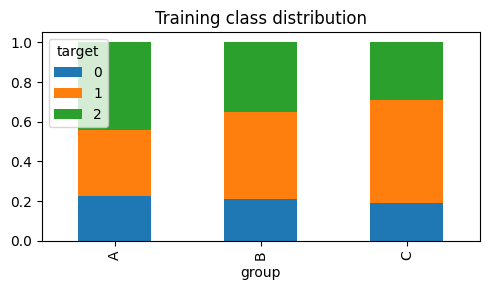

classes: [0, 1, 2]


,metric,value
0,0,75
1,1,156
2,2,129


conclusion: 층화 분리 후 평가 발생률은 유지한다. 클래스 순서와 확률 열 순서를 함께 저장한다.


In [2]:
ctx.run("1-1", "cls_1")

### 1-2

**문제 (10점)**

지정한 여러 분류기와 soft voting을 같은 학습 CV로 비교하시오. 학습 폴드 내부 전처리·지정 sampling·GridSearchCV를 사용하고 macro F1로 선택한 설정과 CV 결과를 기록하시오.

**풀이 근거와 읽는 순서**

sampling은 fit 전에 CV 학습 폴드에만 적용한다.

soft voting은 확률 평균이며 개별 모델보다 좋다는 보장은 없다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [3]:
ctx.run("1-2", "cls_2")

,candidate,cv_macro_f1,parameters
0,logit,0.502043,{'model__C': 0.3}
1,forest,0.470061,{'model__max_depth': 3}
2,boost,0.501258,{}
3,soft_voting,0.478853,{}


selected: logit
sampling: False
conclusion: 학습 CV macro F1로 logit 선택. 확률 평균 앙상블이 항상 개별 후보보다 좋지는 않다.


### 1-3

**문제 (10점)**

선택 후보를 전체 학습 자료에 적합하고 평가 혼동행렬·클래스별 재현율·macro F1·클래스 순서를 제시하시오. 이진 또는 one-vs-rest ROC와 AUC를 ax별로 그리고 확률 보정·임계값 한계를 설명하시오.

**풀이 근거와 읽는 순서**

다중분류 AUC는 클래스별 one-vs-rest를 macro 집계한다.

이진 사건의 점수와 다중 확률 행렬을 혼동하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

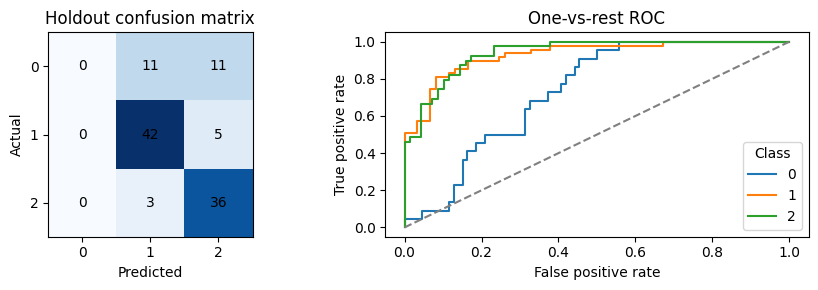

labels: [0, 1, 2]
confusion_matrix: [[0, 11, 11], [0, 42, 5], [0, 3, 36]]
recall_by_class: [0.0, 0.8936170212765957, 0.9230769230769231]
macro_f1: 0.5355809239304384
roc_auc: 0.8677124580173747
auc_definition: macro one-vs-rest
conclusion: 보류 macro F1=0.5356, AUC=0.8677. 최저 재현율 클래스 0=0.0000도 함께 검토해야 한다. 높은 AUC는 확률 보정·최적 비용 임계값을 보장하지 않는다.


In [4]:
ctx.run("1-3", "cls_3")

### 1-4

**문제 (10점)**

라벨 없는 별도 제출 자료를 예측해 id·prediction 열의 submission.csv를 저장하시오. 행 순서·식별자·라벨 정의역·중복·누락을 검사하고 평가 점수와 실제 제출 자료의 성능을 구분하시오.

**풀이 근거와 읽는 순서**

제출용 실제 정답이 없으므로 그 성능을 계산하지 않는다.

최종평가로 임계값·후보를 다시 선택하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [5]:
ctx.run("1-4", "cls_4")

submission_rows: 24
unique_ids: True


,metric,value
0,1,16
1,2,8


,id,prediction
0,361,1
1,362,1
2,363,2
3,364,1
4,365,2


conclusion: 제출 24행을 원 순서로 저장했다. 제출 자료의 정답이 없으므로 실제 제출 정확도는 알 수 없다.


## 2. 계절 수요 예측과 잔차 진단

**상황을 이해하기**

기관은 계절적으로 변하는 수요를 미리 예측해 자원을 준비한다.

**관측 단위와 판단 목적**

한 행은 한 달 또는 한 분기다. 다른 대문항 자료와 결합하지 않는다. 계절 naive와 같은 미래를 비교하고 잔차 진단·구간의 한계를 제시한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `date` | 오름차순 월초/분기초, 중복 없는 등간격 시점 |
| `target` | 해당 기간 합성 수요 지표; 실제 사고/교통 관측 아님 |

**고정 분석 조건**

양수 합성 수요96시점, 월별,period12. 마지막8시점을 최종평가로 봉인한다. 그 이전의 마지막 두4시점을 rolling 검증하며 각 검증 이전 자료만 적합한다. 후보 비계절차수(1,0,0),(0,1,1),(1,1,0), 공통 계절차수(0,1,0,period), trend 없음, maxiter200이다. 수렴 실패 후보는 선택에서 제외하고 모두 실패하면 오류로 보고한다. 검증 RMSE 최소 후보를 선택하며 평가 실제값은 차수 선택에 쓰지 않는다.

### 2-1

**문제 (10점)**

날짜 파싱·간격·중복·결측을 점검하고 마지막8시점을 평가로 봉인하시오. 학습 수준/차분 그림과 ADF 결과를 제시하며 정상성·정규성을 구분하시오.

**풀이 근거와 읽는 순서**

날짜 정렬과 간격을 확인한다.

ADF의 귀무가설은 단위근이며 비기각이 단위근 존재의 증명은 아니다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

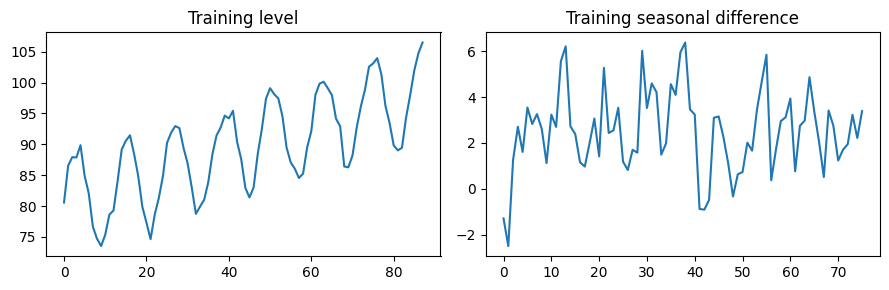

train_end: 87
test_start: 88
period: 12
adf_p: 0.9612413291672294
seasonal_difference_adf_p: 0.00023442879963493873
conclusion: 마지막8시점을 봉인했다. ADF는 단위근에 관한 검정이며 정규성 검정과 다르다.


In [6]:
ctx.run("2-1", "ts_1")

### 2-2

**문제 (10점)**

최종평가 이전의 두 rolling 검증 구간에서 지정 SARIMA 후보를 같은 horizon으로 비교하시오. 평균 RMSE로 후보를 선택하고 각 학습·검증 경계와 실패/수렴 기록을 제시하시오.

**풀이 근거와 읽는 순서**

차수 선택의 대상은 학습 내부 미래 검증이다.

최종8개 관측의 실제값을 차수 선택에 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [7]:
ctx.run("2-2", "ts_2")

,order,cv_rmse,failures
0,"[1, 0, 0]",1.988855,[]
1,"[0, 1, 1]",1.291343,[]
2,"[1, 1, 0]",1.469636,[]


selected_order: [0, 1, 1]
conclusion: rolling 평균 RMSE 최소 차수 [0, 1, 1]를 최종평가 이전에 선택했다.


### 2-3

**문제 (10점)**

선택 차수를 과거 전체에 재적합하고 AIC·BIC·수렴·초기화 구간을 제외한 Ljung-Box 결과를 제시하시오. 잔차 시계열·Q-Q를 ax별로 그리고 남은 가정을 설명하시오.

**풀이 근거와 읽는 순서**

잔차 자유도는 AR/MA 계수 수를 반영한다.

잔차 무상관·정규성이 예측 정확도나 구간의 현장 보정을 증명하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

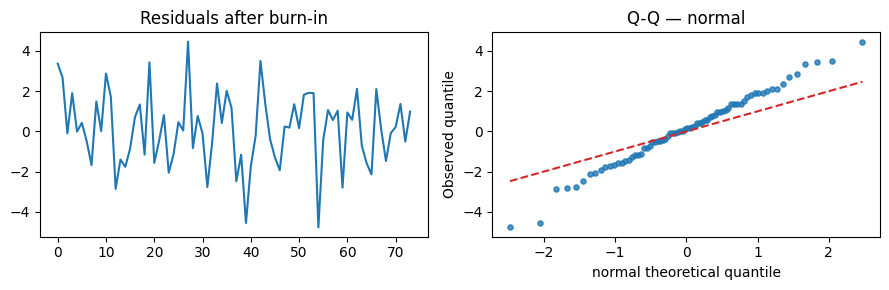

aic: 303.7810841741158
bic: 308.4160604011884
converged: True
burn_in: 14


,lb_stat,lb_pvalue
12,49.046937,9.279930e-07


model_df: 1
conclusion: 수렴=True, 초기14시점 제외. Ljung-Box 비기각은 독립성 전체나 구간 보정을 증명하지 않는다.


In [8]:
ctx.run("2-3", "ts_3")

### 2-4

**문제 (10점)**

같은 미래8시점에서 선택 모형과 계절 naive의 RMSE·MAE·R²·학습 계절차분 분모 MASE를 계산하시오. 95% 조건부 예측구간·관측 포함률을 제시하고 모수/선택 불확실성의 한계를 설명하시오.

**풀이 근거와 읽는 순서**

MASE 분모는 보류 이전 학습만 사용한다.

작은 평가 표본의 포함률을 구간 보장의 증명으로 쓰지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

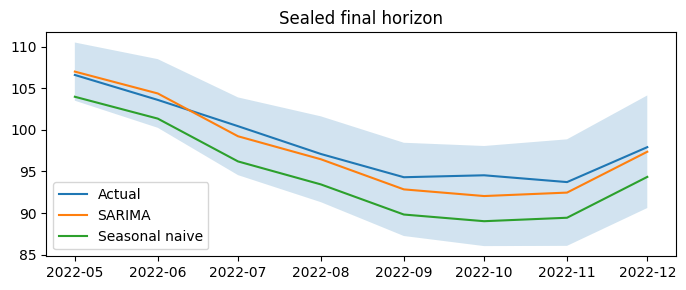

,metric,value
0,rmse,1.268898
1,mae,1.098867
2,r2,0.916160


,metric,value
0,rmse,3.950541
1,mae,3.826771
2,r2,0.187338


mase: 0.4108268156723745
baseline_mase: 1.4306922339323858
mase_denominator: 2.674768712332895
interval_coverage: 1.0
baseline_predictions: [103.973349544, 101.347659356, 96.2044446123, 93.4398962254, 89.8232736107, 89.0227726514, 89.4370889183, 94.3450362099]
conclusion: 원단위 RMSE 1.2689, naive 3.9505, MASE 0.4108. 8개 시점 구간 포함률 1.000를 보장으로 해석하지 않는다.


In [9]:
ctx.run("2-4", "ts_4")

## 3. 학습용 영화평의 품사·빈도·감성

**상황을 이해하기**

상영관별 의견을 단어와 간단한 사전 점수로 요약한다.

**관측 단위와 판단 목적**

한 행은 영화평 한 건이다. 품사는 제공 사전의 표시에만 한정된다. 반복 빈도와 문서빈도, 미등록 단어의 누락을 구분한다.

**변수 사전**

| 열 | 의미·역할 |
| --- | --- |
| `reviews.csv / id` | 문서 식별자 |
| `reviews.csv / group` | 가상 상영관 A/B |
| `reviews.csv / text` | 통제 어휘로 만든 영어 문장; 공백 포함 |
| `lexicon.csv / token` | 등록 영어 단어 |
| `lexicon.csv / pos` | 제공 사전의 품사 NOUN/ADJ/STOP |
| `lexicon.csv / polarity` | 형용사 극성 -1/0/1; 다른 품사는 결측 |

**고정 분석 조건**

영문 합성 영화평60건, id·group·text가 있다. lexicon의 token은 원형, pos는 NOUN/ADJ/STOP, polarity는 형용사에만 -1/0/1이다. 정규식 [a-z]+로 소문자 토큰화하고 NOUN만 빈도에 포함한다. 미등록 토큰은 보존해 일치율을 계산한다. 부정 범위·문맥 품사는 추론하지 않는다.

### 3-1

**문제 (5점)**

문서 식별자·집단·공백 문서·중복을 확인하고 소문자화·영문 토큰 분리를 수행하시오. 제공 사전의 품사·극성·불용어 역할을 설명하시오.

**풀이 근거와 읽는 순서**

일반 자연어 품사 분석기가 아니라 제한된 학습 어휘 사전을 사용하는 과제다.

미등록 단어와 부정어를 기록한다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [10]:
ctx.run("3-1", "text_1")

documents: 60
empty_documents: 8
unique_ids: True
conclusion: 제공 사전의 통제 어휘만 사용한다. 실제 문맥 품사 분석·부정 범위 해석은 수행하지 않는다.


### 3-2

**문제 (5점)**

지정 품사만 남기고 단어별 출현 횟수·문서빈도를 구하시오. 상위 단어 빈도를 ax에 그리고 둘의 분모가 다른 이유를 설명하시오.

**풀이 근거와 읽는 순서**

빈도는 반복 토큰 수, 문서빈도는 그 단어가 한 번 이상 나온 문서 수다.

같은 단어가 반복되어도 문서빈도는 한 번만 센다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

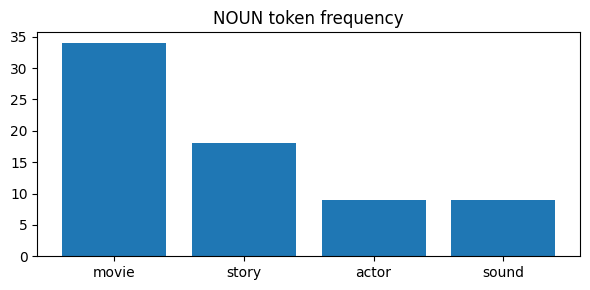

part_of_speech: NOUN


,token,frequency,document_frequency
0,movie,34,26
1,story,18,18
2,actor,9,9
3,sound,9,9


denominator_documents: 60
conclusion: 빈도는 반복 토큰 수이고 문서빈도는 등장 문서 수다. 두 집계를 같은 비율로 해석하지 않는다.


In [11]:
ctx.run("3-2", "text_2")

### 3-3

**문제 (5점)**

문서별 사전 일치율과 형용사 극성 평균을 계산하시오. 일치 단어가 없는 문서의 점수는 결측으로 유지하고 미등록·부정 표현에 대한 규칙의 한계를 설명하시오.

**풀이 근거와 읽는 순서**

점수는 일치 형용사 극성의 평균이며 문장 의미나 인과를 학습한 값이 아니다.

단순히 점수0을 부여하면 중립과 미관측을 섞는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

In [12]:
ctx.run("3-3", "text_3")

scored_documents: 44
unscored_documents: 16
mean_coverage: 0.8461538461538461


,token,count
0,unknownword,8
1,mystery,8


conclusion: 미일치 문서는 결측 점수로 남겼다. not great도 단순 사전에서는great의 양성으로 남으므로 문맥 감성을 판정하지 못한다.


### 3-4

**문제 (5점)**

문서별 결과와 집단별 유효 문서 수·평균 점수를 저장하고 그림으로 비교하시오. 명사 중심 과제에서도 형용사 기반 감성은 별도 보충으로 구분하고 집단의 실제 만족도로 일반화하지 마시오.

**풀이 근거와 읽는 순서**

유효 문서 분모·누락률을 함께 제시한다.

통제된 합성 문장 사전 점수를 실제 감성 평가의 성능으로 제시하지 않는다.

**실행·해석**

다음 셀은 해당 결과를 계산합니다. 수치와 그림을 위 가정·판단 기준에 연결하고 과제 범위를 넘는 인과·현장 결론은 피합니다.

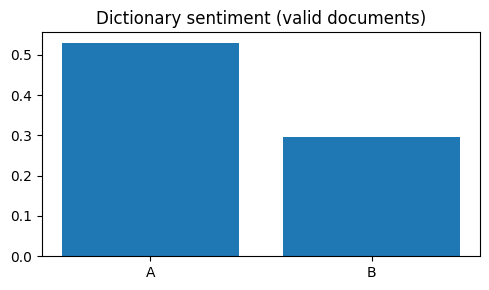

,group,documents,scored,mean_sentiment,mean_coverage
0,A,24,17,0.529412,0.85000
1,B,36,27,0.296296,0.84375


output: document_scores.csv
conclusion: 집단별 유효 문서 수와 일치율을 함께 비교한다. 이 합성 사전 점수는 실제 상영관 만족도의 추정치가 아니다.


In [13]:
ctx.run("3-4", "text_4")